# Machine Learning Laboratory (CSE 4116)
## Relative Humidity Prediction
Inputs: temperature, dewpoint, district, month and hour. Output: humidity (%).

Source: [Mendeley Data v1](https://doi.org/10.17632/htz4fhttr4.1), Rahman, Das, Riya & Nakib (2026), CC BY 4.0.
Humidity in this dataset is calculated from temperature/dewpoint. This experiment learns that relationship; it is not future-weather forecasting.

In Colab, select **Runtime → Run all**. Evaluation years were inspected during development, so independent data are needed for confirmatory validation.

In [ ]:
%pip -q install pandas numpy pyarrow scikit-learn lightgbm matplotlib joblib ipywidgets requests

### 1. Load the dataset

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import hashlib

path = Path("data/dhaka_hourly_core_2015_2025.parquet")
path.parent.mkdir(exist_ok=True)
if not path.exists():
    import requests
    try:
        response = requests.get('https://data.mendeley.com/public-files/datasets/htz4fhttr4/files/274c7e4c-09c8-43bb-882c-56bd681e6cee/file_downloaded', timeout=180)
        response.raise_for_status()
        path.write_bytes(response.content)
    except Exception:
        from google.colab import files
        print("Upload dhaka_hourly_core_2015_2025.parquet from the dataset page.")
        uploaded = files.upload()
        path.write_bytes(uploaded[path.name])
expected = "5890710240a38212a44b5f6e58ad345ba4c6fc8c314da989810e2c38f031fd3b"
assert hashlib.sha256(path.read_bytes()).hexdigest() == expected
columns = ["district", "datetime_utc", "temperature_c", "dewpoint_c", "relative_humidity_pct"]
data = pd.read_parquet(path, columns=columns)
print("Rows:", len(data))
display(data.head())

Rows: 1197144


,district,datetime_utc,temperature_c,dewpoint_c,relative_humidity_pct
0,Dhaka,2015-07-01T00:00:00Z,27.400862,25.793351,90.954586
1,Dhaka,2015-07-01T01:00:00Z,27.281831,25.680013,90.977733
2,Dhaka,2015-07-01T02:00:00Z,29.026428,26.118208,84.341499
3,Dhaka,2015-07-01T03:00:00Z,29.074323,26.223811,84.635001
4,Dhaka,2015-07-01T04:00:00Z,29.176112,26.133997,83.691864


### 2. Check the data and extract month/hour

In [2]:
print(data.isna().sum())
assert not data.isna().any().any()
assert not data.duplicated(["district", "datetime_utc"]).any()
assert np.isfinite(data[["temperature_c", "dewpoint_c", "relative_humidity_pct"]]).all().all()
time = pd.to_datetime(data.datetime_utc, utc=True)
local_time = time.dt.tz_convert("Asia/Dhaka")
data["month"] = local_time.dt.month
data["hour"] = local_time.dt.hour
print("Small source dewpoint excesses:", (data.dewpoint_c > data.temperature_c).sum())
# These 59 precision-scale cases are documented by the source and are preserved.

district                 0
datetime_utc             0
temperature_c            0
dewpoint_c               0
relative_humidity_pct    0
dtype: int64


Small source dewpoint excesses: 59


### 3. Prepare inputs and split by time
Train: 2015–2022. Validation: 2023. Evaluation: 2024–2025. No random train/test mixing.

In [3]:
train_rows = time < "2023-01-01"
valid_rows = (time >= "2023-01-01") & (time < "2024-01-01")
test_rows = time >= "2024-01-01"
districts = sorted(data.loc[train_rows, "district"].unique())

def prepare_inputs(frame):
    x = frame[["temperature_c", "dewpoint_c"]].astype(float).copy()
    x["dewpoint_depression_c"] = x.temperature_c - x.dewpoint_c
    for name, period in [("month", 12), ("hour", 24)]:
        x[name + "_sin"] = np.sin(2 * np.pi * frame[name] / period)
        x[name + "_cos"] = np.cos(2 * np.pi * frame[name] / period)
    for name in districts:
        x["district_" + name] = (frame.district == name).astype(float)
    return x

x = prepare_inputs(data)
y = data.relative_humidity_pct
print("Train / validation / test:", train_rows.sum(), valid_rows.sum(), test_rows.sum())
print("Encoded inputs:", list(x.columns))

Train / validation / test: 855192 113880 228072
Encoded inputs: ['temperature_c', 'dewpoint_c', 'dewpoint_depression_c', 'month_sin', 'month_cos', 'hour_sin', 'hour_cos', 'district_Dhaka', 'district_Faridpur', 'district_Gazipur', 'district_Gopalganj', 'district_Kishoreganj', 'district_Madaripur', 'district_Manikganj', 'district_Munshiganj', 'district_Narayanganj', 'district_Narsingdi', 'district_Rajbari', 'district_Shariatpur', 'district_Tangail']


### 4. Train and compare models
Random Forest uses 150,000 sampled training rows. Linear Regression and LightGBM use all training rows. This compares these configurations, not equal training budgets.

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=60, max_depth=18,
        min_samples_leaf=3, random_state=42, n_jobs=4),
    "LightGBM": LGBMRegressor(n_estimators=350, num_leaves=31,
        learning_rate=0.06, random_state=42, n_jobs=4, verbosity=-1)
}
rows = data.index[train_rows].to_numpy()
forest_rows = np.sort(np.random.default_rng(42).choice(rows, 150000, replace=False))
validation_errors = {}
for name, candidate in models.items():
    fit_rows = forest_rows if name == "Random Forest" else rows
    candidate.fit(x.loc[fit_rows], y.loc[fit_rows])
    predicted = np.clip(candidate.predict(x.loc[valid_rows]), 0, 100)
    validation_errors[name] = mean_absolute_error(y[valid_rows], predicted)
    print(name, "validation MAE:", round(validation_errors[name], 6))
selected = min(validation_errors, key=validation_errors.get)
model = models[selected]
print("Selected model:", selected)

Linear Regression validation MAE: 1.254607


Random Forest validation MAE: 0.014709


LightGBM validation MAE: 0.077615
Selected model: Random Forest


### 5. Evaluate
MAE/RMSE use percentage points. R² is not classification accuracy. Accuracy/F1 below refer only to the separate High humidity ≥85% decision.

In [5]:
from sklearn.metrics import accuracy_score, f1_score
results = []
for name, candidate in models.items():
    predicted = np.clip(candidate.predict(x.loc[test_rows]), 0, 100)
    results.append({"Model": name, "Validation MAE": validation_errors[name],
        "Test MAE": mean_absolute_error(y[test_rows], predicted),
        "Test RMSE": np.sqrt(mean_squared_error(y[test_rows], predicted)),
        "Test R2": r2_score(y[test_rows], predicted)})
results = pd.DataFrame(results)
display(results)
prediction = np.clip(model.predict(x.loc[test_rows]), 0, 100)
actual = y[test_rows].to_numpy()
metrics = {
    "MAE": float(mean_absolute_error(actual, prediction)),
    "RMSE": float(np.sqrt(mean_squared_error(actual, prediction))),
    "R2": float(r2_score(actual, prediction)),
    "within_1pp_percent": float(np.mean(np.abs(actual - prediction) <= 1) * 100),
    "high_humidity_accuracy_percent": float(accuracy_score(actual >= 85, prediction >= 85) * 100),
    "high_humidity_F1": float(f1_score(actual >= 85, prediction >= 85))
}
for name, value in metrics.items():
    print(name, ":", round(value, 6))
# The source formula is a reference, not a trained ML model.
t = data.loc[test_rows, "temperature_c"].to_numpy()
td = data.loc[test_rows, "dewpoint_c"].to_numpy()
reference = np.clip(100 * np.exp(17.67*td/(td+243.5) - 17.67*t/(t+243.5)), 0, 100)
print("Source formula MAE:", mean_absolute_error(actual, reference))

,Model,Validation MAE,Test MAE,Test RMSE,Test R2
0,Linear Regression,1.254607,1.223558,1.808110,0.984802
1,Random Forest,0.014709,0.012408,0.046207,0.999990
2,LightGBM,0.077615,0.071228,0.171876,0.999863


MAE : 0.012408
RMSE : 0.046207
R2 : 0.99999
within_1pp_percent : 99.967116
high_humidity_accuracy_percent : 99.983777
high_humidity_F1 : 0.999837
Source formula MAE: 6.339077894028322e-15


### 6. Plot the results and save the model

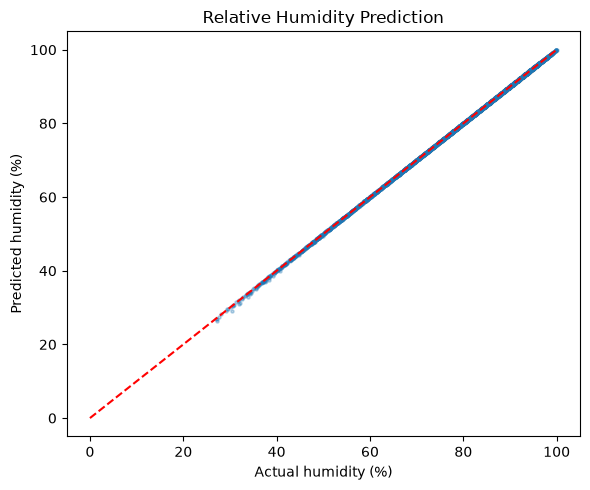

In [6]:
import matplotlib.pyplot as plt
import joblib
import json
out = Path("humidity_outputs")
out.mkdir(exist_ok=True)
limits = {c: {"min": float(data.loc[train_rows, c].min()),
              "max": float(data.loc[train_rows, c].max())} for c in ["temperature_c", "dewpoint_c"]}
joblib.dump({"model": model, "districts": districts, "feature_columns": list(x.columns),
             "limits": limits}, out / "humidity_model.joblib")
(out / "summary.json").write_text(json.dumps(metrics, indent=2))
results.to_csv(out / "model_comparison.csv", index=False)
points = np.random.default_rng(42).choice(len(actual), 5000, replace=False)
plt.figure(figsize=(6, 5))
plt.scatter(actual[points], prediction[points], s=5, alpha=0.3)
plt.plot([0, 100], [0, 100], "r--")
plt.xlabel("Actual humidity (%)")
plt.ylabel("Predicted humidity (%)")
plt.title("Relative Humidity Prediction")
plt.tight_layout()
plt.savefig(out / "actual_vs_predicted.png", dpi=130)
plt.show()

### 7. Try your own inputs

In [7]:
def predict_humidity(temperature, dewpoint, district, month, hour):
    if not np.isfinite([temperature, dewpoint]).all():
        raise ValueError("Temperature and dewpoint must be finite")
    if dewpoint > temperature:
        raise ValueError("Dewpoint must not exceed temperature")
    if district not in districts or month not in range(1, 13) or hour not in range(24):
        raise ValueError("Invalid district, month or hour")
    values = pd.DataFrame([{"temperature_c": temperature, "dewpoint_c": dewpoint,
        "district": district, "month": month, "hour": hour}])
    return float(np.clip(model.predict(prepare_inputs(values))[0], 0, 100))

print("Humidity:", round(predict_humidity(30, 25, "Dhaka", 10, 22), 2), "%")

Humidity: 74.6 %


In [8]:
import ipywidgets as widgets
from IPython.display import display

temperature = widgets.BoundedFloatText(value=30, min=-60, max=60, description="Temp (C)")
dewpoint = widgets.BoundedFloatText(value=25, min=-80, max=60, description="Dewpoint")
district = widgets.Dropdown(options=districts, value="Dhaka", description="District")
month = widgets.Dropdown(options=list(range(1, 13)), value=10, description="Month")
hour = widgets.Dropdown(options=list(range(24)), value=22, description="Hour")
button = widgets.Button(description="Predict Humidity")
output = widgets.Output()

def on_predict(_):
    with output:
        output.clear_output()
        try:
            value = predict_humidity(temperature.value, dewpoint.value, district.value, month.value, hour.value)
            print(f"Humidity: {value:.2f}%")
            for name, value in [("temperature_c", temperature.value), ("dewpoint_c", dewpoint.value)]:
                if not limits[name]["min"] <= value <= limits[name]["max"]:
                    print("Warning: input is outside the training range.")
        except ValueError as error:
            print(error)

button.on_click(on_predict)
display(widgets.VBox([temperature, dewpoint, district, month, hour, button, output]))